# Testing nested clusters for stability

This native Julia companion preserves the original public data, experiments, parameters, sample sizes and decision rules. Saved NumPy random primitives reproduce the original bootstrap, vote, initialization and resampling streams. All tree fitting, greedy k-means++ initialization, Lloyd iterations, clustering, voting and statistics execute in Julia. The native entropy trees retain balanced weights and the original split arithmetic; k-means retains the original iteration and tolerance rules. Ordering within equal cluster labels and tied displayed tree accuracies is stable. Figures use the requested dark theme; outputs remain under `outputs/julia`.

Nested clustering joins the weaker groups, searches inside them again, and keeps the replacement only when average group quality improves:

$$
q_g=\frac{\overline s_g}{\operatorname{sd}(s_g)},
\qquad
\mathcal R=\{g:q_g<\overline q\},
\qquad
\text{accept a new split only if }\overline q_{\mathrm{new}}>\overline q_{\mathcal R}.
$$

Here, $g$ labels a cluster; $s_g$ is its vector of silhouettes; $\overline s_g$ and $\operatorname{sd}(s_g)$ are its mean and spread. $q_g$ is cluster quality; $\overline q$ is the mean across clusters; $\mathcal R$ is the set selected for another search; $\overline q_{\mathrm{new}},\overline q_{\mathcal R}$ compare new and old quality.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("15_predictor_clustering");
using CSV, TOML, Printf
include(joinpath("..","support","BookForest.jl"))
using RiskLabAI.Features: feature_importance_mdi,feature_importance_mda,feature_importance_sfi,clustered_feature_importance_mdi,clustered_feature_importance_mda,orthogonal_features,calculate_weighted_tau,mdi_plus_importance,conditional_predictive_impact
data_path = dataset_path("french_49_industries")
@assert isfile(data_path)
public_lines = readlines(data_path)
header_row = findfirst(startswith(",Agric"),public_lines)
end_row = findnext(line->isempty(strip(line)),public_lines,header_row+1)
raw = CSV.read(IOBuffer(join(public_lines[header_row:end_row-1],"\n")),DataFrame)
rename!(raw,names(raw)[1]=>"Date")
all_dates = Date.(string.(raw.Date),dateformat"yyyymmdd")
all_returns = Matrix{Float64}(raw[:,2:end])
valid = (Date(2019,1,1).<=all_dates).&(all_dates.<=Date(2025,12,31)).&vec(all((all_returns.!=-99.99).&(all_returns.!=-999.0);dims=2))
industry_dates = all_dates[valid]
industry_names = names(raw)[2:end]
industry_returns = all_returns[valid,:]./100
violet = "#C084FC"


selected_features = ["Food","Beer","Hshld","Oil","Coal","Mines","Hardw","Softw","Chips","Banks","Insur","Fin"]
cluster_names = ["Consumer","Resources","Technology","Finance"]
clusters = [name=>collect(3index-2:3index) for (index,name) in enumerate(cluster_names)]
columns = [findfirst(==(name),industry_names) for name in selected_features]

"""Match the public rolling sum's separate add/remove Kahan compensations."""
function rolling_sum(values,window)
    all(isfinite,values) || throw(ArgumentError("complete finite observations are required"))
    result = fill(NaN,length(values))
    total,add_compensation,remove_compensation = 0.,0.,0.
    previous,consecutive = first(values),0
    for index in eachindex(values)
        if index>window
            correction = -values[index-window]-remove_compensation
            updated = total+correction
            remove_compensation = (updated-total)-correction
            total = updated
        end
        value = values[index]
        correction = value-add_compensation
        updated = total+correction
        add_compensation = (updated-total)-correction
        total = updated
        consecutive = value==previous ? consecutive+1 : 1
        previous = value
        if index>=window
            result[index] = consecutive>=window ? previous*window : total
        end
    end
    return result
end

public_x = hcat([rolling_sum(industry_returns[:,column],5)[5:end-1] for column in columns]...)
public_y = Int.(vec(mean(industry_returns[6:end,:];dims=2)).>0)
public_dates = industry_dates[6:end]
include(joinpath("..","support","BookEntropyForest.jl"))
include(joinpath("..","support","BookKMeans.jl"))
include(joinpath("..","support","BookCorrelationArithmetic.jl"))
using RiskLabAI.Ensemble: bagging_classifier_accuracy,bagging_evaluate_schemes,calculate_bootstrap_accuracy
using RiskLabAI.Cluster: cluster_k_means_base,cluster_k_means_top,random_block_correlation,silhouette_samples
split_index = floor(Int,.7length(public_y))
public_x_train,public_x_test = public_x[1:split_index,:],public_x[split_index+1:end,:]
public_y_train,public_y_test = public_y[1:split_index],public_y[split_index+1:end]
input_root = joinpath("..","data","chapter15_random_inputs")
manifest_path = joinpath(input_root,"inputs.toml")
input_manifest = TOML.parsefile(manifest_path)["files"]
input_cache = Dict{String,DataFrame}()

function primitive(name)
    filename = name*".csv"
    return get!(input_cache,filename) do
        path = joinpath(input_root,filename)
        CSV.read(path,DataFrame)
    end
end

table(frame,name,caption) = save_table(frame,paths,name;caption,label="tab:chapter13-"*replace(name,"_"=>"-"))
upper_values(matrix) = [matrix[row,column] for column in 2:size(matrix,2) for row in 1:column-1]
matrix_data(matrix,name) = save_data(DataFrame(matrix,:auto),paths,name)
mean_within(matrix,members) = length(members)<2 ? 1. : mean(upper_values(matrix[members,members]))

function histogram_edges(values,bins,name;density=false)
    edges = collect(range(minimum(values),maximum(values);length=bins+1))
    edges[end] = nextfloat(edges[end])
    counts = [count(value->edges[index]<=value<edges[index+1],values) for index in 1:bins]
    @assert sum(counts)==length(values)
    heights = density ? counts./length(values)./diff(edges) : Float64.(counts)
    save_data(DataFrame(lower=edges[1:end-1],upper=edges[2:end],count=counts,height=heights),paths,name*"_histogram")
    return edges
end

function labels_from_clusters(n,groups)
    labels = zeros(Int,n)
    for (group,members) in groups
        labels[members] .= group
    end
    return labels
end

adjusted_rand(first,second) = BookCorrelationArithmeticCandidate.adjusted_rand(first,second)

candidate_fits,candidate_labels = NamedTuple[],NamedTuple[]

function candidate_provider(seed,context)
    inputs = Matrix(primitive("kmeans_$(seed)"))
    counters = IdDict{Any,Int}()
    runs = IdDict{Any,Int}()
    function provider(features,k,rng)
        if !haskey(counters,rng)
            counters[rng] = 0
            runs[rng] = length(runs)+1
            matrix_data(features,"kmeans_inputs_$(context)_$(runs[rng])")
        end
        step = counters[rng]+1
        counters[rng] = step
        count = 1+(k-1)*(2+floor(Int,log(k)))
        fitted = BookKMeans.fit_kmeans(features,k,inputs[step,2:count+1])
        fit = length(candidate_fits)+1
        push!(candidate_fits,(fit=fit,context=context,run=runs[rng],step=step,clusters=k,seed=Int(inputs[step,1]),observations=size(features,1),iterations=fitted.iterations,inertia=fitted.inertia,initial=join(fitted.initial_indices,"|")))
        append!(candidate_labels,[(fit=fit,row=index,label=value) for (index,value) in enumerate(fitted.labels)])
        return fitted.labels
    end
    return provider
end

function cluster_fit(correlation,seed,context;nested=false,max_clusters=12,iterations=20)
    provider = candidate_provider(seed,context)
    routine = nested ? cluster_k_means_top : cluster_k_means_base
    result = routine(correlation;max_clusters,iterations,random_state=seed,label_provider=provider)
    labels = labels_from_clusters(size(correlation,1),result[2])
    save_data(DataFrame(label=labels,silhouette=result[3]),paths,"partition_"*context)
    matrix_data(correlation,"correlation_"*context)
    return result
end

function save_candidates(name)
    save_data(DataFrame(candidate_fits),paths,name*"_candidate_fits")
    save_data(DataFrame(candidate_labels),paths,name*"_candidate_labels")
    return nothing
end

function cluster_summary(correlation,groups,scores;quality=false)
    rows = NamedTuple[]
    for key in sort(collect(keys(groups)))
        members = groups[key]
        base = (Cluster=key+1,Size=length(members),Mean=mean(scores[members]),Minimum=minimum(scores[members]))
        if quality
            spread = std(scores[members])
            base = merge(base,(Quality=spread>0 ? mean(scores[members])/spread : Inf,))
        end
        push!(rows,merge(base,(Correlation=mean_within(correlation,members),Industries=join(industry_names[members],", "))))
    end
    frame = DataFrame(rows)
    rename!(frame,:Mean=>"Mean silhouette",:Minimum=>"Minimum silhouette",:Correlation=>"Mean within correlation")
    return frame
end

function correlation_panel(matrix,title;labels=nothing)
    n = size(matrix,1)
    ticks = labels===nothing ? false : (1:n,labels)
    return heatmap(1:n,1:n,matrix;color=cgrad([palette.rose,"#D1D5DB",palette.cyan]),clims=(-1,1),colorbar_title="Correlation",title,xticks=ticks,yticks=ticks,xrotation=90,tickfontsize=6,yflip=true,aspect_ratio=:equal,xlims=(.5,n+.5),ylims=(.5,n+.5),widen=false)
end


correlation_panel (generic function with 1 method)

## Nested Public Clusters

In [2]:
public_correlation = BookCorrelationArithmeticCandidate.pandas_correlation(industry_returns)
base_sorted,base_clusters,base_silhouette = cluster_fit(public_correlation,13031,"nested_base")
nested_sorted,nested_clusters,nested_silhouette = cluster_fit(public_correlation,13031,"nested_full";nested=true)
base_labels = labels_from_clusters(49,base_clusters)
nested_labels = labels_from_clusters(49,nested_clusters)
nested_cluster_summary = cluster_summary(public_correlation,nested_clusters,nested_silhouette;quality=true)
table(nested_cluster_summary,"nested_cluster_summary","Nested public industry clusters.");


Row,Cluster,Size,Mean silhouette,Minimum silhouette,Quality,Mean within correlation,Industries
,Int64,Int64,Float64,Float64,Float64,Float64,String
1,1,2,0.29608,0.221033,2.7897,0.222696,"Gold, Coal"
2,2,47,0.396057,-0.0433426,2.55485,0.597059,"Agric, Food, Soda, Beer, Smoke, Toys, Fun, Books, Hshld, Clths, Hlth, MedEq, Drugs, Chems, Rubbr, Txtls, BldMt, Cnstr, Steel, FabPr, Mach, ElcEq, Autos, Aero, Ships, Guns, Mines, Oil, Util, Telcm, PerSv, BusSv, Hardw, Softw, Chips, LabEq, Paper, Boxes, Trans, Whlsl, Rtail, Meals, Banks, Insur, RlEst, Fin, Other"


The co-membership matrix records how often two industries stay together, while adjusted Rand agreement compares two full partitions after removing chance agreement:

$$
M_{ij}=\frac{1}{B}\sum_{b=1}^{B}\mathbf 1\!\left\{z_i^{(b)}=z_j^{(b)}\right\},
\qquad
\operatorname{ARI}
=\frac{\sum_{gh}{n_{gh}\choose2}-\dfrac{\sum_g{a_g\choose2}\sum_h{b_h\choose2}}{{n\choose2}}}
{\dfrac12\!\left[\sum_g{a_g\choose2}+\sum_h{b_h\choose2}\right]-\dfrac{\sum_g{a_g\choose2}\sum_h{b_h\choose2}}{{n\choose2}}}.
$$

Here, $B$ is the number of resampled histories; $z_i^{(b)}$ is industry $i$'s cluster label in repetition $b$; $M_{ij}\in[0,1]$ is their joining frequency. $n_{gh}$ counts items shared by cluster $g$ in one partition and $h$ in the other; $a_g,b_h$ are cluster sizes; $n$ is item count; ${m\choose2}$ counts pairs; ARI is adjusted Rand agreement.

## Circular Block Resampling

Row,Quantity,Value
,String,Float64
1,Resampled histories,24.0
2,Block length in days,20.0
3,Reference clusters,2.0
4,Mean resampled clusters,2.45833
5,Minimum adjusted Rand agreement,0.0885278
6,Mean adjusted Rand agreement,0.220271
7,Maximum adjusted Rand agreement,1.0
8,Mean resampled silhouette,0.274436


Row,Cluster,Size,Mean within-cluster co-membership,Industries
,Int64,Int64,Float64,String
1,1,2,0.958333,"Gold, Coal"
2,2,47,0.645313,"Agric, Food, Soda, Beer, Smoke, Toys, Fun, Books, Hshld, Clths, Hlth, MedEq, Drugs, Chems, Rubbr, Txtls, BldMt, Cnstr, Steel, FabPr, Mach, ElcEq, Autos, Aero, Ships, Guns, Mines, Oil, Util, Telcm, PerSv, BusSv, Hardw, Softw, Chips, LabEq, Paper, Boxes, Trans, Whlsl, Rtail, Meals, Banks, Insur, RlEst, Fin, Other"


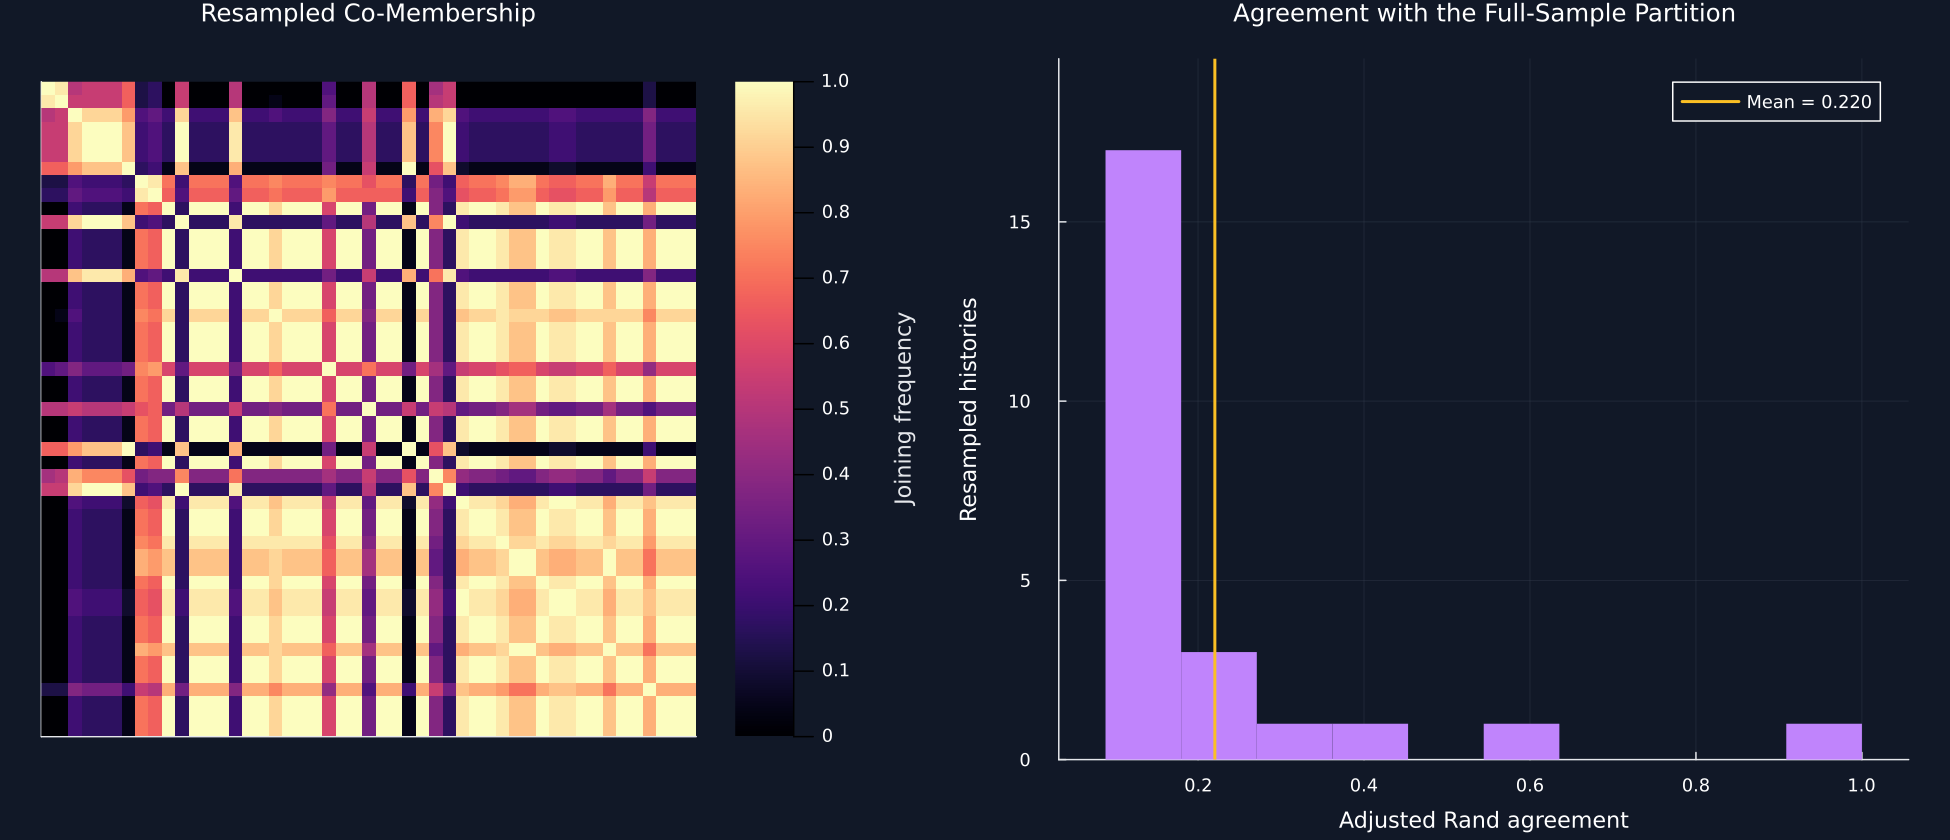

In [3]:
stability_runs,block_length = 24,20
membership_sum = zeros(49,49)
stability_rows = NamedTuple[]
stability_label_vectors = Vector{Int}[]
resample_positions = Matrix{Int}(primitive("stability_positions"))
for repetition in 1:stability_runs
    current_correlation = BookCorrelationArithmeticCandidate.pandas_correlation(industry_returns[resample_positions[:,repetition],:])
    _,groups,scores = cluster_fit(current_correlation,13099+repetition,"stability_$(repetition)";nested=true,iterations=8)
    labels = labels_from_clusters(49,groups)
    push!(stability_label_vectors,labels)
    membership_sum .+= labels.==transpose(labels)
    push!(stability_rows,(Repetition=repetition,Clusters=length(groups),Agreement=adjusted_rand(nested_labels,labels),Mean=mean(scores)))
end
public_stability_paths = DataFrame(stability_rows)
rename!(public_stability_paths,:Agreement=>"Adjusted Rand agreement",:Mean=>"Mean silhouette")
public_membership = membership_sum./stability_runs
public_stability_summary = DataFrame("Quantity"=>["Resampled histories","Block length in days","Reference clusters","Mean resampled clusters","Minimum adjusted Rand agreement","Mean adjusted Rand agreement","Maximum adjusted Rand agreement","Mean resampled silhouette"],"Value"=>[stability_runs,block_length,length(nested_clusters),mean(public_stability_paths.Clusters),minimum(public_stability_paths[!,"Adjusted Rand agreement"]),mean(public_stability_paths[!,"Adjusted Rand agreement"]),maximum(public_stability_paths[!,"Adjusted Rand agreement"]),mean(public_stability_paths[!,"Mean silhouette"])])
table(public_stability_summary,"public_stability_summary","Circular block-resampling stability of the public nested clusters.")
public_stability_by_cluster = DataFrame([(Cluster=key+1,Size=length(nested_clusters[key]),Frequency=mean_within(public_membership,nested_clusters[key]),Industries=join(industry_names[nested_clusters[key]],", ")) for key in sort(collect(keys(nested_clusters)))])
rename!(public_stability_by_cluster,:Frequency=>"Mean within-cluster co-membership")
table(public_stability_by_cluster,"public_stability_by_cluster","Resampled joining frequency within each reference cluster.")
save_data(public_stability_paths,paths,"public_stability_paths")
matrix_data(public_membership,"public_membership")
matrix_data(hcat(stability_label_vectors...),"public_stability_labels")
nested_order = sortperm(nested_labels)
first_panel = heatmap(public_membership[nested_order,nested_order];color=:magma,clims=(0,1),colorbar_title="Joining frequency",title="Resampled Co-Membership",xticks=false,yticks=false,yflip=true,aspect_ratio=:equal,xlims=(.5,49.5),ylims=(.5,49.5),widen=false)
agreements = public_stability_paths[!,"Adjusted Rand agreement"]
second_panel = histogram(agreements;bins=histogram_edges(agreements,10,"public_stability"),color=violet,linealpha=0,label=false,title="Agreement with the Full-Sample Partition",xlabel="Adjusted Rand agreement",ylabel="Resampled histories")
vline!(second_panel,[mean(agreements)];color=palette.amber,label=@sprintf("Mean = %.3f",mean(agreements)))
ylims!(second_panel,(0,1.15last(ylims(second_panel))))
save_figure(plot(first_panel,second_panel;layout=(1,2),size=(1300,560)),paths,"public_cluster_stability");


## Known Block Recovery

The controlled benchmark adds five known covariance blocks to a common component, then converts the result to correlation before hiding the original order:

$$
\Sigma=\operatorname{blockdiag}(\Sigma_1,\ldots,\Sigma_G)+\Sigma_m,
\qquad
R_{ij}=\frac{\Sigma_{ij}}{\sqrt{\Sigma_{ii}\Sigma_{jj}}},
\qquad
G=5.
$$

Here, $\Sigma_g$ is the covariance block for group $g$; $G=5$ is the known group count; $\operatorname{blockdiag}$ places blocks on the diagonal. $\Sigma_m$ is the shared component; $\Sigma$ is total covariance; $R_{ij}$ is correlation; $i,j$ label the $30$ controlled series; diagonal terms are variances.

Row,Repetition,True clusters,Base clusters,Nested clusters,Base adjusted Rand agreement,Nested adjusted Rand agreement
,Int64,Int64,Int64,Int64,Float64,Float64
1,1,5,5,5,1.0,1.0
2,2,5,5,5,1.0,1.0
3,3,5,5,5,1.0,1.0
4,4,5,5,5,1.0,1.0
5,5,5,5,5,1.0,1.0
6,6,5,5,5,1.0,1.0
7,7,5,5,5,1.0,1.0
8,8,5,5,5,1.0,1.0
9,9,5,5,5,1.0,1.0


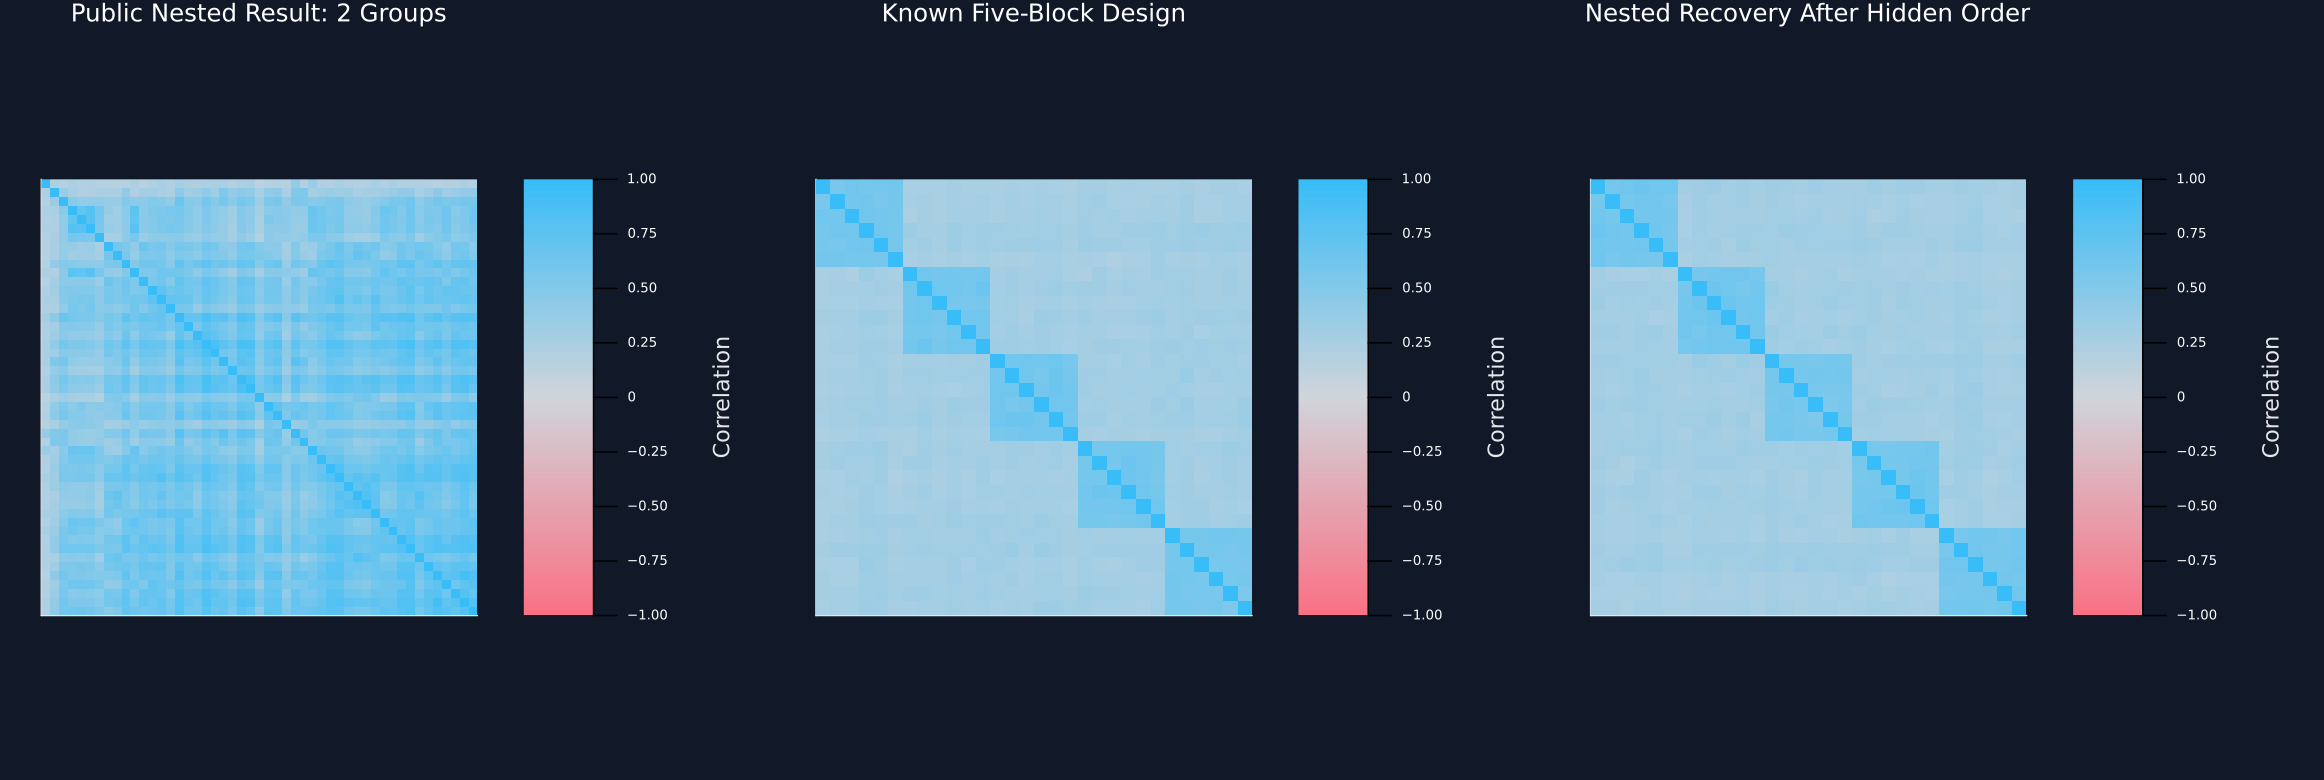

In [4]:
controlled_rows = NamedTuple[]
controlled_example,controlled_example_sorted = nothing,nothing
for repetition in 1:12
    block_inputs = [Matrix(primitive("block_$(repetition)_part_$(index)")) for index in 1:5]
    market = Matrix(primitive("block_$(repetition)_market"))
    draws = (cuts=primitive("block_$(repetition)_cuts").cut,blocks=[(common=values[:,1],noise=values[:,2:end]) for values in block_inputs],market=(common=market[:,1],noise=market[:,2:end]))
    current_correlation = BookCorrelationArithmeticCandidate.random_block_correlation(30,5;block_size_min=6,random_state=13199+repetition,draws)
    permutation = primitive("block_$(repetition)_permutation").position
    true_labels = repeat(0:4;inner=6)
    hidden_correlation = current_correlation[permutation,permutation]
    hidden_truth = true_labels[permutation]
    _,current_base_clusters,_ = cluster_fit(hidden_correlation,13399+repetition,"control_base_$(repetition)";max_clusters=10,iterations=10)
    current_nested_sorted,current_nested_clusters,_ = cluster_fit(hidden_correlation,13399+repetition,"control_nested_$(repetition)";nested=true,max_clusters=10,iterations=10)
    current_base_labels = labels_from_clusters(30,current_base_clusters)
    current_nested_labels = labels_from_clusters(30,current_nested_clusters)
    push!(controlled_rows,(Repetition=repetition,Truth=5,Base=length(current_base_clusters),Nested=length(current_nested_clusters),BaseAgreement=adjusted_rand(hidden_truth,current_base_labels),NestedAgreement=adjusted_rand(hidden_truth,current_nested_labels)))
    matrix_data(current_correlation,"controlled_correlation_$(repetition)")
    if repetition==1
        global controlled_example = current_correlation
        global controlled_example_sorted = current_nested_sorted
    end
end
controlled_recovery = DataFrame(controlled_rows)
rename!(controlled_recovery,:Truth=>"True clusters",:Base=>"Base clusters",:Nested=>"Nested clusters",:BaseAgreement=>"Base adjusted Rand agreement",:NestedAgreement=>"Nested adjusted Rand agreement")
table(controlled_recovery,"controlled_recovery","Known-block recovery over twelve fixed-seed correlation designs.")
save_candidates("nested")
figure = plot(correlation_panel(nested_sorted,"Public Nested Result: $(length(nested_clusters)) Groups"),correlation_panel(controlled_example,"Known Five-Block Design"),correlation_panel(controlled_example_sorted,"Nested Recovery After Hidden Order");layout=(1,3),size=(1550,520))
save_figure(figure,paths,"public_nested_clusters");


## Tests

In [5]:
@assert size(industry_returns)==(1760,49)
@assert size(public_correlation)==(49,49)
@assert 2<=length(base_clusters)<=12
@assert 2<=length(nested_clusters)<=12
@assert sum(length,values(nested_clusters))==49
@assert Set(reduce(vcat,values(nested_clusters)))==Set(1:49)
@assert size(nested_sorted)==(49,49)
@assert length(nested_silhouette)==49
@assert all(-1 .<=nested_silhouette.<=1)
@assert size(nested_cluster_summary)==(length(nested_clusters),7)
@assert sum(nested_cluster_summary.Size)==49
@assert all(-1 .<=nested_cluster_summary[!,"Mean within correlation"].<=1)
@assert size(public_stability_paths)==(24,4)
@assert all(2 .<=public_stability_paths.Clusters.<=12)
@assert all(-1 .<=public_stability_paths[!,"Adjusted Rand agreement"].<=1)
@assert all(-1 .<=public_stability_paths[!,"Mean silhouette"].<=1)
@assert size(public_membership)==(49,49)
@assert public_membership≈transpose(public_membership)
@assert diag(public_membership)≈ones(49)
@assert minimum(public_membership)>=0
@assert maximum(public_membership)<=1
@assert size(public_stability_summary)==(8,2)
@assert size(public_stability_by_cluster)==(length(nested_clusters),4)
@assert all(0 .<=public_stability_by_cluster[!,"Mean within-cluster co-membership"].<=1)
@assert size(controlled_recovery)==(12,6)
@assert all(controlled_recovery[!,"True clusters"].==5)
@assert all(-1 .<=controlled_recovery[!,"Base adjusted Rand agreement"].<=1)
@assert all(-1 .<=controlled_recovery[!,"Nested adjusted Rand agreement"].<=1)
@assert mean(controlled_recovery[!,"Base adjusted Rand agreement"])>.85
@assert mean(controlled_recovery[!,"Nested adjusted Rand agreement"])>.85
@assert size(controlled_example)==(30,30)
@assert size(controlled_example_sorted)==(30,30)
@assert length(stability_label_vectors)==24
@assert size(resample_positions)==(1760,24)
@assert all(1 .<=resample_positions.<=1760)
@assert all(isfinite,controlled_example)
@assert diag(controlled_example)≈ones(30)
@assert isfile(joinpath(paths.figures,"public_cluster_stability.pdf"))
@assert isfile(joinpath(paths.figures,"public_nested_clusters.pdf"))
@assert isfile(joinpath(paths.tables,"nested_cluster_summary.tex"))
@assert isfile(joinpath(paths.tables,"public_stability_summary.tex"))
@assert isfile(joinpath(paths.tables,"public_stability_by_cluster.tex"))
@assert isfile(joinpath(paths.tables,"controlled_recovery.tex"))
println("Native nested selection, 24 block histories and twelve known-block recovery assertions passed.");


Native nested selection, 24 block histories and twelve known-block recovery assertions passed.
